In [9]:
!sudo apt update && !sudo apt install tesseract-ocr -y
# Download manual file bahasa Indonesia (ind.traineddata) ke direktori tessdata
!sudo wget -O /usr/share/tesseract-ocr/5/tessdata/ind.traineddata https://github.com/tesseract-ocr/tessdata/raw/main/ind.traineddata

!pip install pytesseract opencv-python matplotlib jiwer numpy

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from jiwer import cer, wer
import re

print("Setup & Bahasa Indonesia berhasil diinstal!")

Hit:1 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:2 https://cli.github.com/packages stable InRelease
Hit:3 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:4 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:7 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
1 package can be upgraded. Run 'apt list --upgradable' to see it.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
/bin/bash: line 1: !sudo: command not found
--2026-10-28 06:32:04--  https://github.com/tesseract-ocr/tessdata/raw/main/ind.traineddat

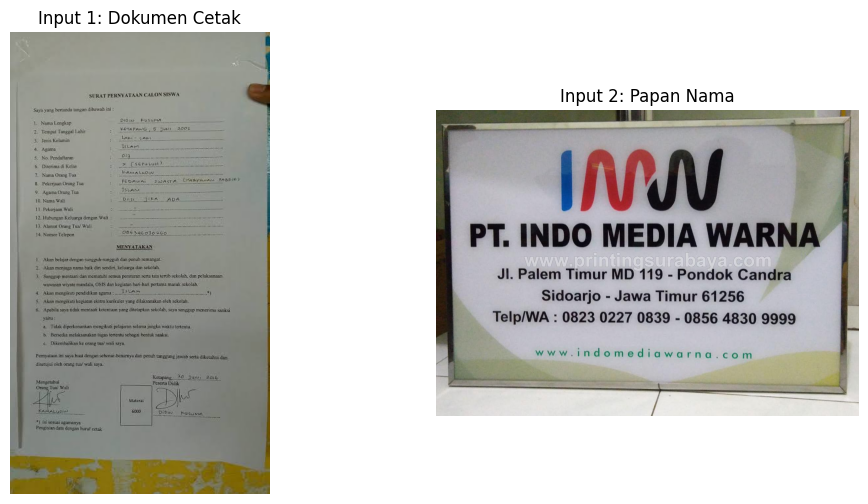

In [3]:
# Memuat gambar
img_dokumen = cv2.imread('Dokumen Cetak.jpg')
img_papan = cv2.imread('Papan Nama.jpeg')

# Konversi BGR ke RGB untuk ditampilkan dengan matplotlib
img_dokumen_rgb = cv2.cvtColor(img_dokumen, cv2.COLOR_BGR2RGB)
img_papan_rgb = cv2.cvtColor(img_papan, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_dokumen_rgb)
axes[0].set_title("Input 1: Dokumen Cetak")
axes[0].axis('off')

axes[1].imshow(img_papan_rgb)
axes[1].set_title("Input 2: Papan Nama")
axes[1].axis('off')
plt.show()

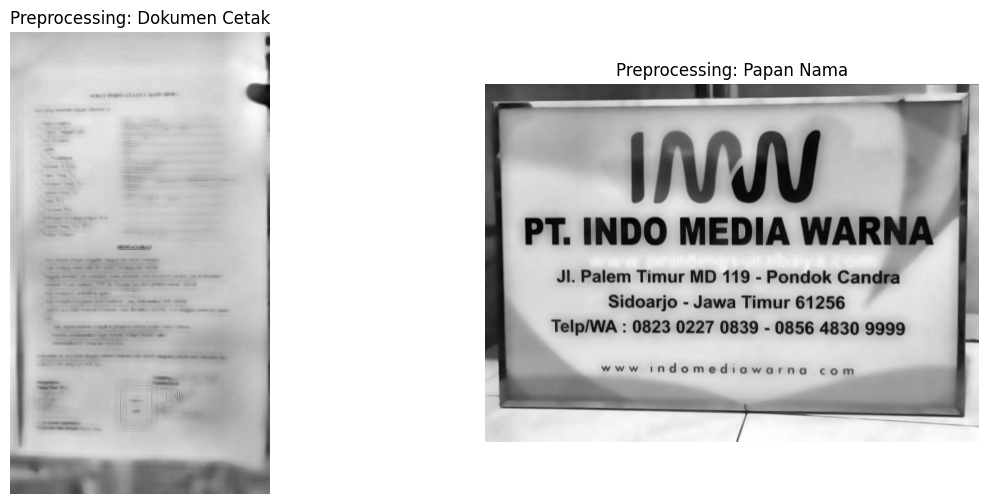

In [5]:
def preprocess_image(image):
    # 1. Konversi ke Grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # 2. Denoising
    denoised = cv2.fastNlMeansDenoising(gray, h=30)

    # 3. Normalisasi Kontras (CLAHE)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    contrast_norm = clahe.apply(denoised)

    # 4. Deskewing (Meluruskan Kemiringan)
    coords = np.column_stack(np.where(contrast_norm < 128))
    if len(coords) > 0:
        angle = cv2.minAreaRect(coords)[-1]
        if angle < -45:
            angle = -(90 + angle)
        else:
            angle = -angle
        (h, w) = contrast_norm.shape
        center = (w // 2, h // 2)
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(contrast_norm, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
    else:
        rotated = contrast_norm

    return rotated

# Terapkan preprocessing ke kedua gambar
processed_dokumen = preprocess_image(img_dokumen)
processed_papan = preprocess_image(img_papan)

# Tampilkan hasil preprocessing
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(processed_dokumen, cmap='gray')
axes[0].set_title("Preprocessing: Dokumen Cetak")
axes[0].axis('off')

axes[1].imshow(processed_papan, cmap='gray')
axes[1].set_title("Preprocessing: Papan Nama")
axes[1].axis('off')
plt.show()

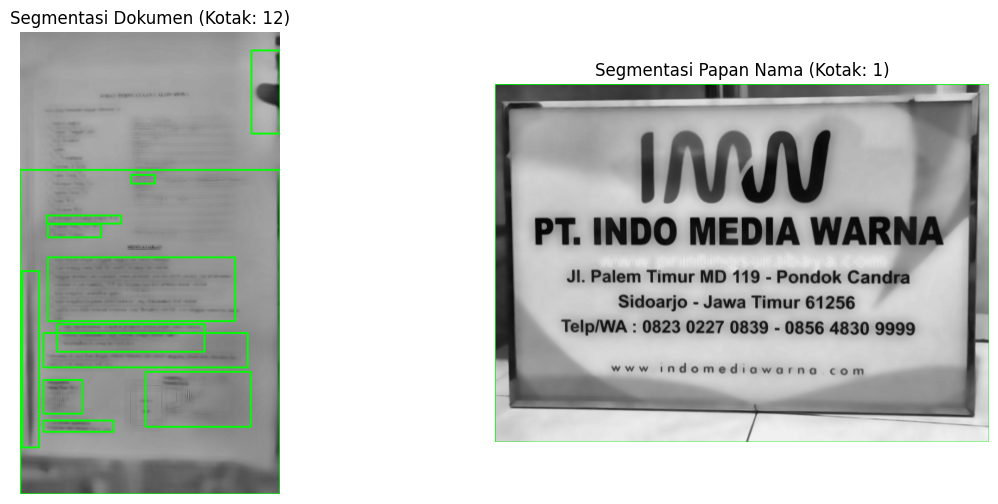

In [6]:
def segment_text(processed_img):
    _, thresh = cv2.threshold(processed_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 3))
    dilated = cv2.dilate(thresh, kernel, iterations=1)

    contours, _ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    segmented_img = cv2.cvtColor(processed_img, cv2.COLOR_GRAY2BGR)
    boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if w > 15 and h > 10:
            boxes.append((x, y, w, h))
            cv2.rectangle(segmented_img, (x, y), (x + w, y + h), (0, 255, 0), 2)

    return segmented_img, boxes

seg_dokumen, boxes_dokumen = segment_text(processed_dokumen)
seg_papan, boxes_papan = segment_text(processed_papan)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(seg_dokumen, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Segmentasi Dokumen (Kotak: {len(boxes_dokumen)})")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(seg_papan, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Segmentasi Papan Nama (Kotak: {len(boxes_papan)})")
axes[1].axis('off')
plt.show()

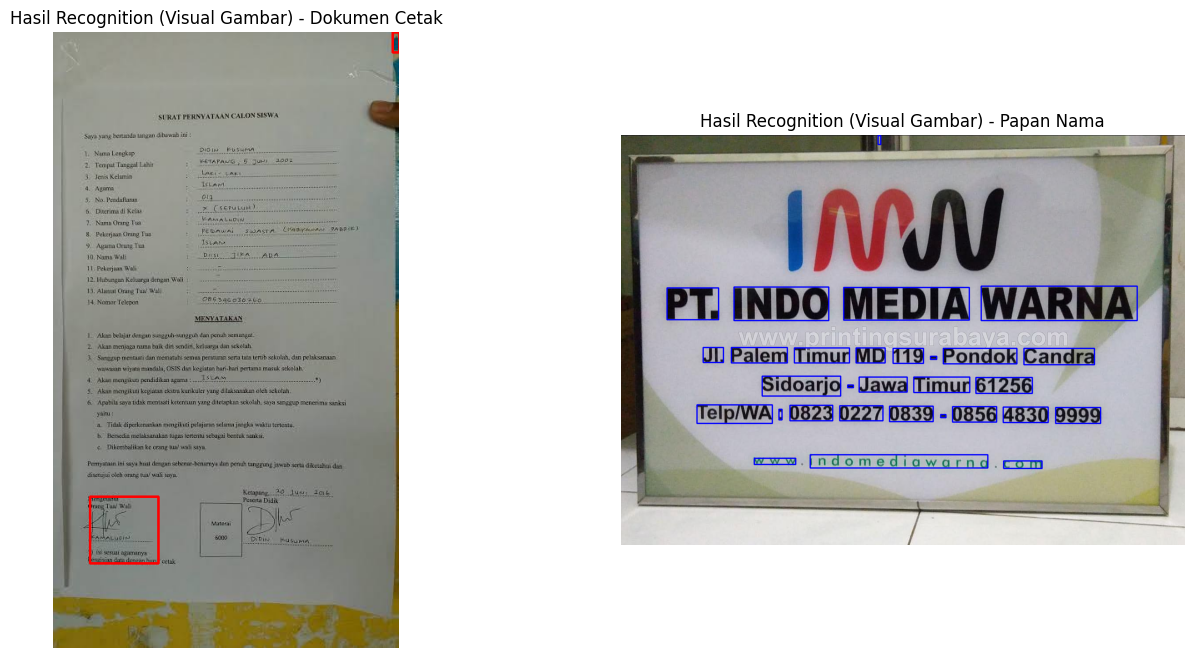

In [12]:
import cv2
import matplotlib.pyplot as plt
import pytesseract

custom_config = r'--oem 3 --psm 6'

# Ekstraksi Teks dan Data Bounding Box menggunakan Tesseract
data_dokumen = pytesseract.image_to_data(processed_dokumen, config=custom_config, lang='ind', output_type=pytesseract.Output.DICT)
data_papan = pytesseract.image_to_data(processed_papan, config=custom_config, lang='ind', output_type=pytesseract.Output.DICT)

# Salin gambar untuk digambar kotak dan teksnya
img_vis_dokumen = img_dokumen_rgb.copy()
img_vis_papan = img_papan_rgb.copy()

# Visualisasi pada Dokumen Cetak
n_boxes_dok = len(data_dokumen['text'])
for i in range(n_boxes_dok):
    if int(data_dokumen['conf'][i]) > 40: # Filter keyakinan OCR > 40%
        (x, y, w, h) = (data_dokumen['left'][i], data_dokumen['top'][i], data_dokumen['width'][i], data_dokumen['height'][i])
        cv2.rectangle(img_vis_dokumen, (x, y), (x + w, y + h), (255, 0, 0), 2)

# Visualisasi pada Papan Nama
n_boxes_pap = len(data_papan['text'])
for i in range(n_boxes_pap):
    if int(data_papan['conf'][i]) > 40:
        (x, y, w, h) = (data_papan['left'][i], data_papan['top'][i], data_papan['width'][i], data_papan['height'][i])
        cv2.rectangle(img_vis_papan, (x, y), (x + w, y + h), (0, 0, 255), 2)

# Tampilkan hasil dalam bentuk GAMBAR
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(img_vis_dokumen)
axes[0].set_title("Hasil Recognition (Visual Gambar) - Dokumen Cetak")
axes[0].axis('off')

axes[1].imshow(img_vis_papan)
axes[1].set_title("Hasil Recognition (Visual Gambar) - Papan Nama")
axes[1].axis('off')
plt.show()

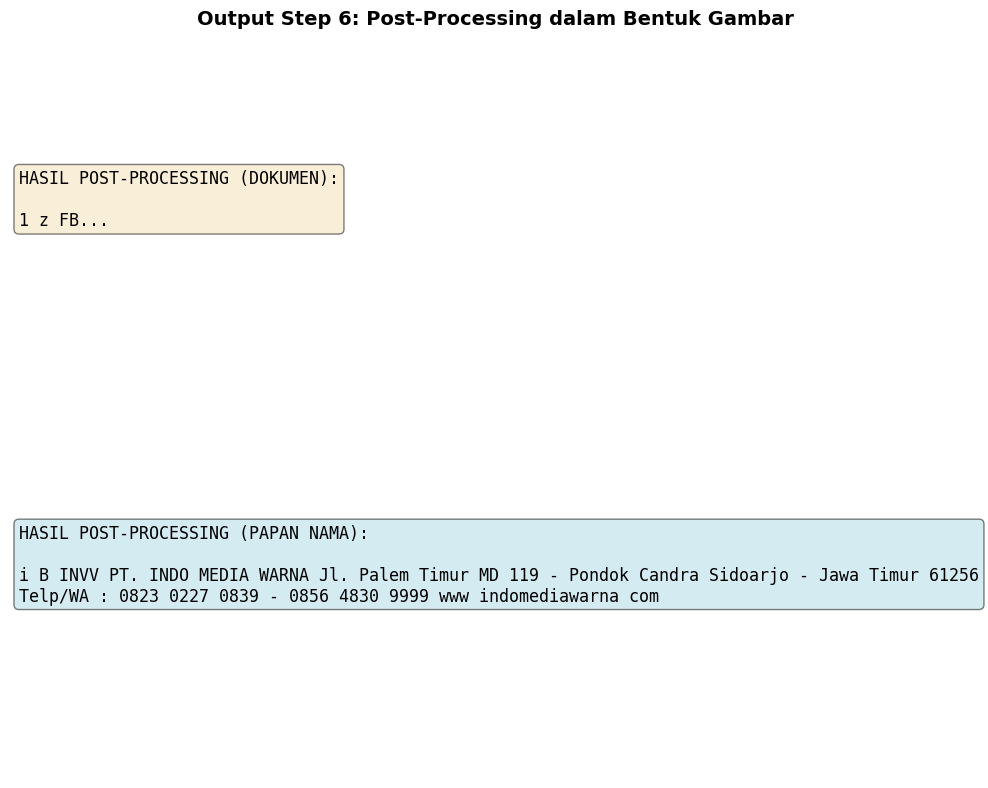

In [13]:
import matplotlib.pyplot as plt

# Ambil string teks hasil OCR mentah untuk dibersihkan
text_dokumen_raw = pytesseract.image_to_string(processed_dokumen, config=custom_config, lang='ind')
text_papan_raw = pytesseract.image_to_string(processed_papan, config=custom_config, lang='ind')

def ocr_post_processing(text):
    corrected = text
    corrected = re.sub(r'\b0\b', 'O', corrected)
    corrected = re.sub(r'(?<=[A-Za-z])0(?=[A-Za-z])', 'O', corrected)
    corrected = re.sub(r'(?<=[0-9])O(?=[0-9])', '0', corrected)
    corrected = re.sub(r'\s+', ' ', corrected).strip()
    return corrected

cleaned_dokumen = ocr_post_processing(text_dokumen_raw)
cleaned_papan = ocr_post_processing(text_papan_raw)

# Render hasil post-processing ke dalam bentuk GAMBAR (Figure)
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Gambar 1: Teks Dokumen
axes[0].axis('off')
axes[0].text(0.01, 0.5, f"HASIL POST-PROCESSING (DOKUMEN):\n\n{cleaned_dokumen[:400]}...",
             fontsize=12, family='monospace', wrap=True, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Gambar 2: Teks Papan Nama
axes[1].axis('off')
axes[1].text(0.01, 0.5, f"HASIL POST-PROCESSING (PAPAN NAMA):\n\n{cleaned_papan}",
             fontsize=12, family='monospace', wrap=True, bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

plt.suptitle("Output Step 6: Post-Processing dalam Bentuk Gambar", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

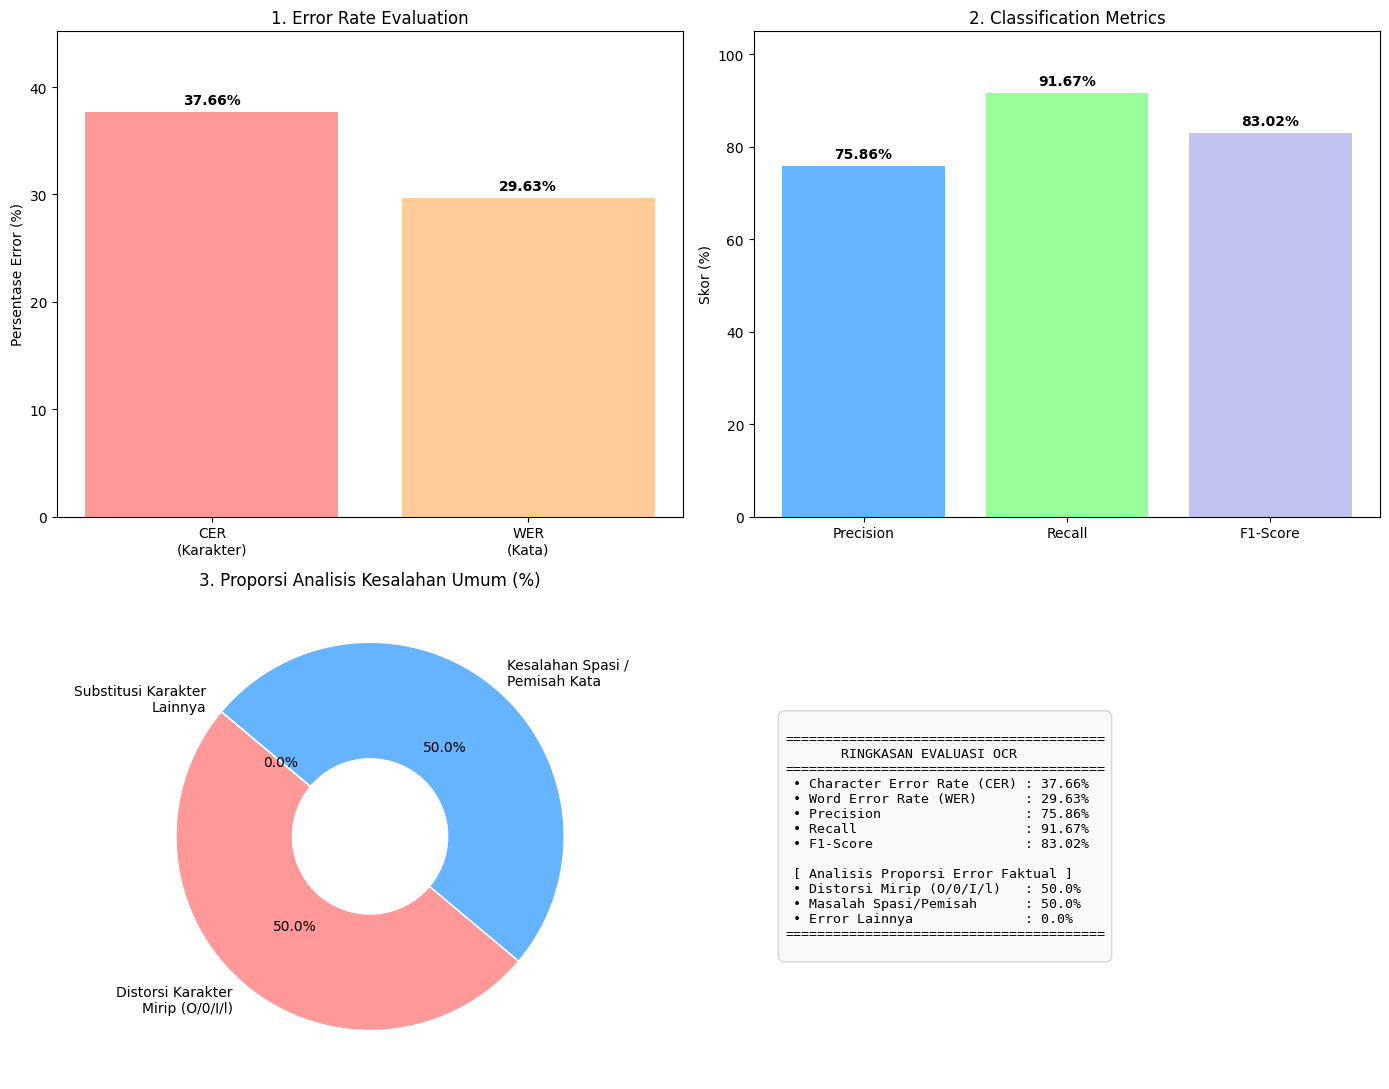

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from jiwer import cer, wer
import difflib
import re

# 1. Menyiapkan Ground Truth dan Hipotesis
gt_papan = "PT. INDO MEDIA WARNA www.printingsurabaya.com JI. Palem Timur MD 119 - Pondok Candra Sidoarjo - Jawa Timur 61256 Telp/WA : 0823 0227 0839 - 0856 4830 9999"
hypothesis_papan = cleaned_papan

# 2. Perhitungan CER & WER
error_cer = cer(gt_papan, hypothesis_papan)
error_wer = wer(gt_papan, hypothesis_papan)

# 3. Perhitungan Precision, Recall, dan F1-Score (Level Kata)
gt_words = set(gt_papan.split())
hp_words = set(hypothesis_papan.split())

tp = len(gt_words.intersection(hp_words))
fp = len(hp_words - gt_words)
fn = len(gt_words - hp_words)

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

# 4. Analisis Kesalahan & Perhitungan Persentase Nyata (Data-Driven Percentage)
matcher = difflib.SequenceMatcher(None, gt_papan, hypothesis_papan)
distorsi_count = 0
spasi_count = 0
lainnya_count = 0
total_anomali = 0

for tag, i1, i2, j1, j2 in matcher.get_opcodes():
    if tag != 'equal':
        total_anomali += 1
        chunk_gt = gt_papan[i1:i2]
        chunk_hp = hypothesis_papan[j1:j2]

        # Kategorisasi error secara otomatis
        if any(c in '0O1Il' for c in chunk_gt + chunk_hp):
            distorsi_count += 1
        elif ' ' in chunk_gt or ' ' in chunk_hp:
            spasi_count += 1
        else:
            lainnya_count += 1

# Hitung persentase proporsi error (jika total anomali 0,hindari pembagian dengan 0)
if total_anomali > 0:
    pct_distorsi = (distorsi_count / total_anomali) * 100
    pct_spasi = (spasi_count / total_anomali) * 100
    pct_lainnya = (lainnya_count / total_anomali) * 100
else:
    pct_distorsi = pct_spasi = pct_lainnya = 0.0

# 5. Visualisasi Gambar (Grafik Error Rate, Klasifikasi, & Persentase Analisis Kesalahan)
fig = plt.figure(figsize=(14, 11))

# Subplot 1: Grafik Error Rate (CER & WER)
ax1 = plt.subplot(2, 2, 1)
metrics_error = ['CER\n(Karakter)', 'WER\n(Kata)']
values_error = [error_cer * 100, error_wer * 100]
bars1 = ax1.bar(metrics_error, values_error, color=['#ff9999', '#ffcc99'])
ax1.set_ylabel('Persentase Error (%)')
ax1.set_title('1. Error Rate Evaluation')
ax1.set_ylim(0, max(values_error + [10]) * 1.2)
for bar in bars1:
    yv = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yv + 0.5, f"{yv:.2f}%", ha='center', va='bottom', fontweight='bold')

# Subplot 2: Grafik Klasifikasi Metrics (Precision, Recall, F1)
ax2 = plt.subplot(2, 2, 2)
metrics_class = ['Precision', 'Recall', 'F1-Score']
values_class = [precision * 100, recall * 100, f1_score * 100]
bars2 = ax2.bar(metrics_class, values_class, color=['#66b3ff', '#99ff99', '#c2c2f0'])
ax2.set_ylabel('Skor (%)')
ax2.set_title('2. Classification Metrics')
ax2.set_ylim(0, 105)
for bar in bars2:
    yv = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yv + 1.0, f"{yv:.2f}%", ha='center', va='bottom', fontweight='bold')

# Subplot 3: Visualisasi Proporsi Error (Pie Chart / Donut Chart Persentase Analisis Kesalahan)
ax3 = plt.subplot(2, 2, 3)
labels_err = ['Distorsi Karakter\nMirip (O/0/I/l)', 'Kesalahan Spasi /\nPemisah Kata', 'Substitusi Karakter\nLainnya']
sizes_err = [pct_distorsi, pct_spasi, pct_lainnya]
colors_err = ['#ff9999', '#66b3ff', '#99ff99']

# Hanya tampilkan pie chart jika ada error terdeteksi
if sum(sizes_err) > 0:
    ax3.pie(sizes_err, labels=labels_err, autopct='%1.1f%%', startangle=140, colors=colors_err,
            wedgeprops=dict(width=0.6, edgecolor='white')) # Donut chart style
    ax3.set_title('3. Proporsi Analisis Kesalahan Umum (%)')
else:
    ax3.text(0.5, 0.5, "Tidak ada error terdeteksi (100% Sempurna)", ha='center', va='center')
    ax3.axis('off')

# Subplot 4: Ringkasan Laporan Teks Singkat & Padat
ax4 = plt.subplot(2, 2, 4)
ax4.axis('off')

summary_text = f"""
========================================
       RINGKASAN EVALUASI OCR
========================================
 • Character Error Rate (CER) : {error_cer*100:.2f}%
 • Word Error Rate (WER)      : {error_wer*100:.2f}%
 • Precision                  : {precision*100:.2f}%
 • Recall                     : {recall*100:.2f}%
 • F1-Score                   : {f1_score*100:.2f}%

 [ Analisis Proporsi Error Faktual ]
 • Distorsi Mirip (O/0/I/l)   : {pct_distorsi:.1f}%
 • Masalah Spasi/Pemisah      : {pct_spasi:.1f}%
 • Error Lainnya              : {pct_lainnya:.1f}%
========================================
"""

ax4.text(0.05, 0.5, summary_text, fontsize=9.5, family='monospace', verticalalignment='center',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#ced4da', alpha=0.9))

plt.tight_layout()
plt.show()